In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import kagglehub
path = kagglehub.dataset_download("blastchar/telco-customer-churn")
from kagglehub import KaggleDatasetAdapter

import os
print(os.listdir(path))

import glob
files = glob.glob(path + "/*.csv")

from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV

import sklearn.metrics as metrics
from sklearn.metrics import recall_score, precision_score, f1_score, accuracy_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report


from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier
from xgboost import plot_importance

from sklearn.preprocessing import StandardScaler

Using Colab cache for faster access to the 'telco-customer-churn' dataset.
['WA_Fn-UseC_-Telco-Customer-Churn.csv']


In [2]:
df = pd.read_csv('/kaggle/input/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv', encoding='latin1')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# **Exploratory Analysis**

In [3]:
# Gather basic information about the data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [4]:
# Check for missing values in the dataset
df.isna().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


When attempting to convert the TotalCharges column to float, it becomes apparent that there are likely some empty values.

In [5]:
# Check for empty values in TotalCharges column
df.loc[pd.to_numeric(df['TotalCharges'], errors='coerce').isna(), 'TotalCharges'].unique()

array([' '], dtype=object)

In [6]:
# Convert TotalCharges column to numeric
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [7]:
# Check for missing total charges values by tenure
print('Missing values:', df['TotalCharges'].isna().sum())
df.loc[df['TotalCharges'].isna(), ['tenure', 'TotalCharges']]

Missing values: 11


,tenure,TotalCharges
488,0,NaN
753,0,NaN
936,0,NaN
1082,0,NaN
1340,0,NaN
3331,0,NaN
3826,0,NaN
4380,0,NaN
5218,0,NaN
6670,0,NaN


There are 11 missing values in TotalCharges. All 11 of these customers have a tenure of 0 months, which suggests that they may not have accumulated any charges yet. This could explain the missing values.
Therefore, we will replace these NaNs with 0.

In [8]:
# Replace NaNs with 0
df['TotalCharges'] = df['TotalCharges'].fillna(0)
df['TotalCharges'].isna().sum()

np.int64(0)

In [9]:
# Gather descriptive statistics about the data
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


In [10]:
# Check for duplicates
df.duplicated().sum()

np.int64(0)

In [11]:
# Analysis of churn
print('Number of churn:', df['Churn'].value_counts())
print('Percentage of churn:', df['Churn'].value_counts(normalize=True))

Number of churn: Churn
No     5174
Yes    1869
Name: count, dtype: int64
Percentage of churn: Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64


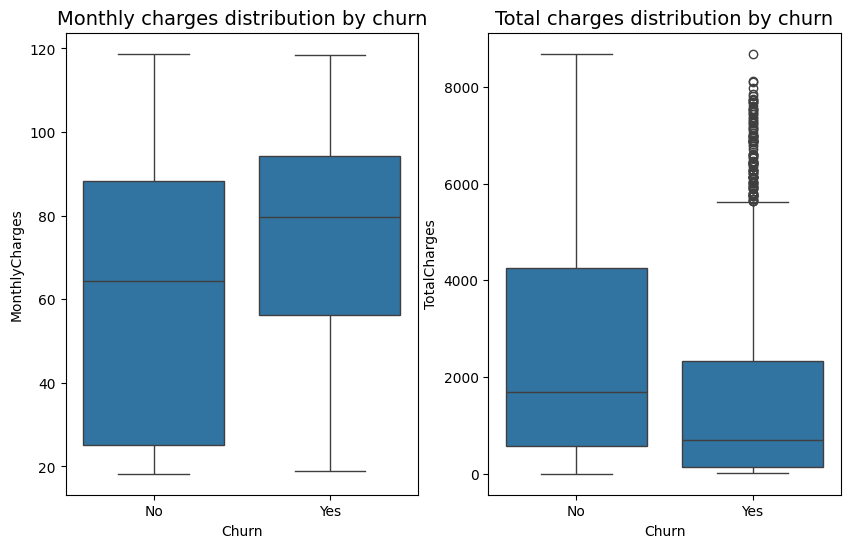

In [12]:
# Boxplots to visualize monthly and total charges distribution by churn
fig, ax = plt.subplots(1, 2, figsize = (10,6))

sns.boxplot(data=df, x='Churn', y='MonthlyCharges', ax=ax[0])
ax[0].set_title('Monthly charges distribution by churn', fontsize='14')

sns.boxplot(data=df, x='Churn', y='TotalCharges', ax=ax[1])
ax[1].set_title('Total charges distribution by churn', fontsize='14')
plt.show()

- Monthly charges: Customers who churned have a higher median monthly charge (approximately 80 dollars) than customers who stayed (approximately $65). This suggests an association between higher monthly charges and churn, although the distributions overlap substantially. Further analysis is needed to determine whether churn rates differ across monthly charge levels.

- Total charges: Customers who churned generally have lower total charges than customers who stayed. This may be related to shorter customer tenure, since customers who stay longer have more time to accumulate charges. Comparing tenure across churn groups would help investigate this hypothesis.

These observations identify potential relationships between billing variables and churn.








**Churn rates by tenure groups**

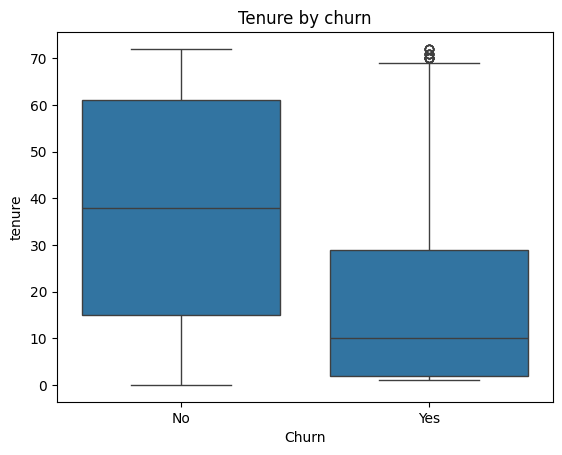

In [13]:
# Tenure by churn boxplot
sns.boxplot(data = df, x = 'Churn', y = 'tenure')
plt.title('Tenure by churn')
plt.show()

The boxplot reveals a clear difference in median tenure between the two groups (customers who churned and those who stayed). The median tenure for customers who churned is less than 10 months, whereas for those who stayed, it is substantially higher, at approximately 38 months. This suggests that churn is more strongly associated with shorter customer tenure.

Now, let's calculate the churn rate for three tenure groups:

- 0 to 12 months
- 13 to 36 months
- 37 months and more

In [14]:
# Create a categorical variable that assigns each customer to a tenure group
categories = ['0-12 months', '13-36 months', '37 months+']
df['tenure_group'] = pd.cut(df['tenure'], bins = [-1, 12, 36, 72], labels = categories, right = True)
df['tenure_group'].value_counts()

,count
tenure_group,
37 months+,3001
0-12 months,2186
13-36 months,1856


In [15]:
# Churn rate by tenure groups
df['yes_churn'] = (df['Churn'] == 'Yes')
(df.groupby('tenure_group', observed=False)['yes_churn'].mean())*100

,yes_churn
tenure_group,
0-12 months,47.438243
13-36 months,25.538793
37 months+,11.929357


The churn rate is highest among customers with a tenure of 0–12 months, at 47.44%. It decreases to 25.54% for customers with a tenure of 13–36 months and to 11.93% for those with a tenure of more than 36 months.

These results strengthen our previous observation that churn is associated with shorter customer tenure.

**Churn rates by contract type**

In [16]:
# Analysis of contracts
df['Contract'].value_counts()

,count
Contract,
Month-to-month,3875
Two year,1695
One year,1473


In [17]:
# Comparison of churn by contract type
pd.crosstab(df['Contract'], df['Churn'])

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


In [18]:
# Percentage of churn by contract type
pd.crosstab(df['Contract'], df['Churn'], normalize='index')*100

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


The churn rate is highest among customers with a month-to-month contract, at 42.7%. It decreases as contract duration increases, reaching 11.27% for customers with a one-year contract and 2.83% for those with a two-year contract.

These results show a strong association between contract type and churn: customers with shorter-term contracts are more likely to leave.

Further analysis is needed to determine whether this relationship is also influenced by factors such as monthly charges.

**Churn rates by monthly charges**

In [19]:
# Monthly charges statistics
df['MonthlyCharges'].describe()

,MonthlyCharges
count,7043.000000
mean,64.761692
std,30.090047
min,18.250000
25%,35.500000
50%,70.350000
75%,89.850000
max,118.750000


In [20]:
# Separate MonthlyCharges into different groups
groups = ['Low', 'Medium', 'High']
charges_cat, intervals = pd.qcut(df['MonthlyCharges'], q=3, labels=groups, retbins=True)
print(charges_cat.value_counts())
print("Intervals:", intervals)

MonthlyCharges
Low       2351
High      2347
Medium    2345
Name: count, dtype: int64
Intervals: [ 18.25  50.4   83.9  118.75]


Low: $18.25 - 50.40 ➡ 2351 clients

Medium: $50.40 - 83.90 ➡ 2345 clients

High: $83.90 - 118.75 ➡ 2347 clients

In [21]:
# Churn rates by monthly charges groups
(df.groupby(charges_cat, observed=False)['yes_churn'].mean())*100

,yes_churn
MonthlyCharges,
Low,15.865589
Medium,29.680171
High,34.086067


The churn rate increases across monthly charge categories, from 15.87% among customers with low monthly charges to 34.09% among those with high monthly charges. This suggests an association between higher monthly charges and a greater likelihood of churn.

**Churn rates by subscribed services**

*Online security*

In [22]:
# Online Security counts
df['OnlineSecurity'].value_counts()

,count
OnlineSecurity,
No,3498
Yes,2019
No internet service,1526


In [23]:
# Churn rates by online security categories
(df.groupby('OnlineSecurity', observed=False)['yes_churn'].mean())*100

,yes_churn
OnlineSecurity,
No,41.766724
No internet service,7.404980
Yes,14.611194


*Tech Support*

In [24]:
# Tech Support count
df['TechSupport'].value_counts( )

,count
TechSupport,
No,3473
Yes,2044
No internet service,1526


In [25]:
# Churn rates by tech support categories
(df.groupby('TechSupport', observed=False)['yes_churn'].mean())*100

,yes_churn
TechSupport,
No,41.635474
No internet service,7.404980
Yes,15.166341


The churn rate is higher among customers who do not subscribe to online security (41.77%) or tech support (41.64%) than among those who subscribe to these services. Customers without an internet service have a considerably lower churn rate (7.40%).

These results suggest an association between subscription status for these services and churn.

# **Modeling**

In [26]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,tenure_group,yes_churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0-12 months,False
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,One year,No,Mailed check,56.95,1889.50,No,13-36 months,False
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,0-12 months,True
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,37 months+,False
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,0-12 months,True


In [27]:
# Replace churn column with binary values
df_enc = df.copy()
df_enc['Churn'] = df_enc['Churn'].replace({'Yes': 1, 'No': 0})
df_enc.head()

/tmp/ipykernel_283/906161506.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_enc['Churn'] = df_enc['Churn'].replace({'Yes': 1, 'No': 0})


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,tenure_group,yes_churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0,0-12 months,False
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,One year,No,Mailed check,56.95,1889.50,0,13-36 months,False
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1,0-12 months,True
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0,37 months+,False
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1,0-12 months,True


In [28]:
# Select the outcome and the features we want to use in our model
y = df_enc['Churn']
X = df_enc.drop(['Churn', 'yes_churn', 'customerID'], axis = 1)

In [29]:
# Data encoding for other column
X = pd.get_dummies(X, drop_first=False)
X.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,...,Contract_Two year,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,tenure_group_0-12 months,tenure_group_13-36 months,tenure_group_37 months+
0,0,1,29.85,29.85,True,False,False,True,True,False,...,False,False,True,False,False,True,False,True,False,False
1,0,34,56.95,1889.50,False,True,True,False,True,False,...,False,True,False,False,False,False,True,False,True,False
2,0,2,53.85,108.15,False,True,True,False,True,False,...,False,False,True,False,False,False,True,True,False,False
3,0,45,42.30,1840.75,False,True,True,False,True,False,...,False,True,False,True,False,False,False,False,False,True
4,0,2,70.70,151.65,True,False,True,False,True,False,...,False,False,True,False,False,True,False,True,False,False


In [30]:
X.columns

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges',
       'gender_Female', 'gender_Male', 'Partner_No', 'Partner_Yes',
       'Dependents_No', 'Dependents_Yes', 'PhoneService_No',
       'PhoneService_Yes', 'MultipleLines_No',
       'MultipleLines_No phone service', 'MultipleLines_Yes',
       'InternetService_DSL', 'InternetService_Fiber optic',
       'InternetService_No', 'OnlineSecurity_No',
       'OnlineSecurity_No internet service', 'OnlineSecurity_Yes',
       'OnlineBackup_No', 'OnlineBackup_No internet service',
       'OnlineBackup_Yes', 'DeviceProtection_No',
       'DeviceProtection_No internet service', 'DeviceProtection_Yes',
       'TechSupport_No', 'TechSupport_No internet service', 'TechSupport_Yes',
       'StreamingTV_No', 'StreamingTV_No internet service', 'StreamingTV_Yes',
       'StreamingMovies_No', 'StreamingMovies_No internet service',
       'StreamingMovies_Yes', 'Contract_Month-to-month', 'Contract_One year',
       'Contract_Two year', '

In [31]:
# Split the model
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)

### Logistic regression

In [32]:
# Scale the features
scaler = StandardScaler().fit(X_train)

X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [33]:
# Train the model
log_reg = LogisticRegression(random_state=42).fit(X_train_scaled, y_train)

In [34]:
# Generate predictions
y_pred = log_reg.predict(X_test_scaled)

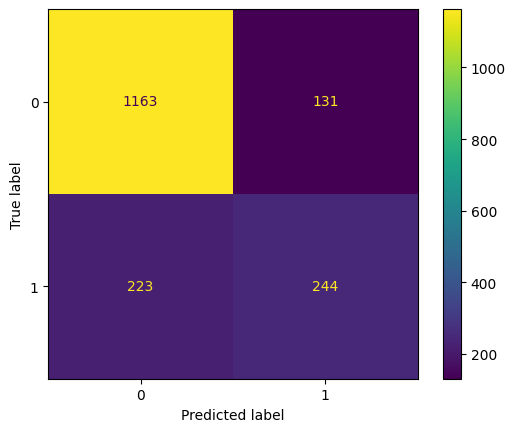

In [35]:
# Confusion matrix
log_cm = confusion_matrix(y_test, y_pred, labels=log_reg.classes_)

log_disp = ConfusionMatrixDisplay(confusion_matrix=log_cm, display_labels=log_reg.classes_)
log_disp.plot(values_format='')

In [36]:
# Classification report for the model
target_names = ['Predicted would not churn', 'Predicted would churn']
print(classification_report(y_test, y_pred, target_names=target_names))

                           precision    recall  f1-score   support

Predicted would not churn       0.84      0.90      0.87      1294
    Predicted would churn       0.65      0.52      0.58       467

                 accuracy                           0.80      1761
                macro avg       0.74      0.71      0.72      1761
             weighted avg       0.79      0.80      0.79      1761



### Random Forest

In [37]:
rf = RandomForestClassifier(random_state=42)

In [38]:
# Dictionary of hyperparameters
rf_params = {'n_estimators' : [100, 200],
             'max_depth' : [5, None],
             'min_samples_leaf' : [1, 3],
             'min_samples_split' : [2, 5],
             'max_features' : ['sqrt']}

# List of scoring metrics
scoring = ['precision', 'accuracy', 'recall', 'f1']

# Instantiate GridSearch
rf_cv = GridSearchCV(rf, rf_params, scoring = scoring, cv = 4, refit ='recall', n_jobs = -1, verbose = 2)

In [39]:
%%time

# Fit the rf model to the training data
rf_cv.fit(X_train, y_train)

Fitting 4 folds for each of 16 candidates, totalling 64 fits
CPU times: user 909 ms, sys: 52.1 ms, total: 962 ms
Wall time: 57.1 s


GridSearchCV(cv=4, estimator=RandomForestClassifier(random_state=42), n_jobs=-1,
             param_grid={'max_depth': [5, None], 'max_features': ['sqrt'],
                         'min_samples_leaf': [1, 3],
                         'min_samples_split': [2, 5],
                         'n_estimators': [100, 200]},
             refit='recall', scoring=['precision', 'accuracy', 'recall', 'f1'],
             verbose=2)

In [40]:
# Check the best parameters
rf_cv.best_params_

{'max_depth': None,
 'max_features': 'sqrt',
 'min_samples_leaf': 3,
 'min_samples_split': 2,
 'n_estimators': 100}

In [41]:
# Evaluate the rf model on test set
best_rf = rf_cv.best_estimator_

# Generate predictions
y_pred_rf = best_rf.predict(X_test)

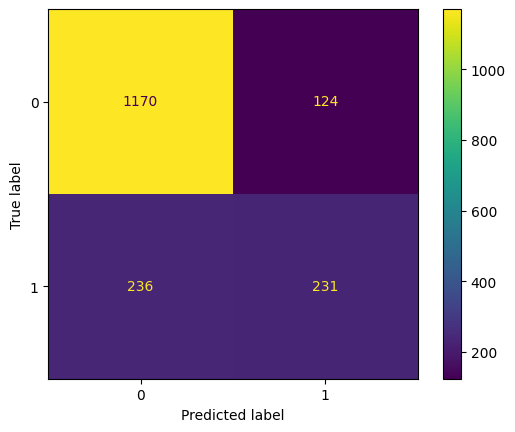

In [42]:
# Confusion matrix
log_cm = confusion_matrix(y_test, y_pred_rf, labels=rf_cv.classes_)

log_disp = ConfusionMatrixDisplay(confusion_matrix=log_cm, display_labels=rf_cv.classes_)
log_disp.plot(values_format='')

In [43]:
results = pd.DataFrame(columns=['Model', 'F1', 'Recall', 'Precision', 'Accuracy'])

def make_results(model_name, y_true, y_pred):

  return pd.DataFrame({'Model': [model_name],
                        'F1': [f1_score(y_true, y_pred)],
                        'Recall': [recall_score(y_true, y_pred)],
                        'Precision': [precision_score(y_true, y_pred)],
                        'Accuracy': [accuracy_score(y_true, y_pred)]
                        }
                       )

In [44]:
results = pd.concat([
    make_results('Logistic Regression', y_test, y_pred),
    make_results('Random Forest', y_test, y_pred_rf)], ignore_index=True)

print(results.round(3))

                 Model     F1  Recall  Precision  Accuracy
0  Logistic Regression  0.580   0.522      0.651     0.799
1        Random Forest  0.562   0.495      0.651     0.796


### XGBoost

In [45]:
xgb = XGBClassifier(objective='binary:logistic',  eval_metric='logloss', random_state=42)

In [46]:
# Model parameters
xgb_params = {'max_depth': [3, 5],
              'min_child_weight': [1, 3],
              'learning_rate': [0.1, 0.2],
              'n_estimators': [100, 200],
              'subsample': [0.8],
              'colsample_bytree': [0.8]
              }

# List of scoring metrics
scoring = ['precision', 'accuracy', 'recall', 'f1']

# Instantiate GridSearch
xgb_cv = GridSearchCV(xgb, xgb_params, scoring = scoring, cv = 4, refit ='recall', n_jobs = -1, verbose = 2)

In [47]:
%%time

# Fit the XGBoost model to the training data
xgb_cv.fit(X_train, y_train)

Fitting 4 folds for each of 16 candidates, totalling 64 fits
CPU times: user 564 ms, sys: 25.7 ms, total: 589 ms
Wall time: 13.7 s


GridSearchCV(cv=4,
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=None, device=None,
                                     early_stopping_rounds=None,
                                     enable_categorical=True,
                                     eval_metric='logloss', feature_types=None,
                                     feature_weights=None, gamma=None,
                                     grow_policy=None, importance_type=None,
                                     interaction_constraints...
                                     max_leaves=None, min_child_weight=None,
                                     missing=nan, monotone_constraints=None,
                                     multi_strategy=None, n_estimators=None,
                                     n_jobs=None, num_parallel_tree=None, ...),
             n_jobs=-1,
             param_grid={'colsample_bytree': [0.8], 'learning_rate': [0.1, 0.2],
                         'max_depth': [3, 5], 'min_child_weight': [1, 3],
                         'n_estimators': [100, 200], 'subsample': [0.8]},
             refit='recall', scoring=['precision', 'accuracy', 'recall', 'f1'],
             verbose=2)

In [48]:
# Check the best parameters
xgb_cv.best_params_

{'colsample_bytree': 0.8,
 'learning_rate': 0.1,
 'max_depth': 3,
 'min_child_weight': 3,
 'n_estimators': 100,
 'subsample': 0.8}

In [49]:
# Evaluate the xgb model on test set
best_xgb = xgb_cv.best_estimator_

# Generate predictions
y_pred_xgb = best_xgb.predict(X_test)

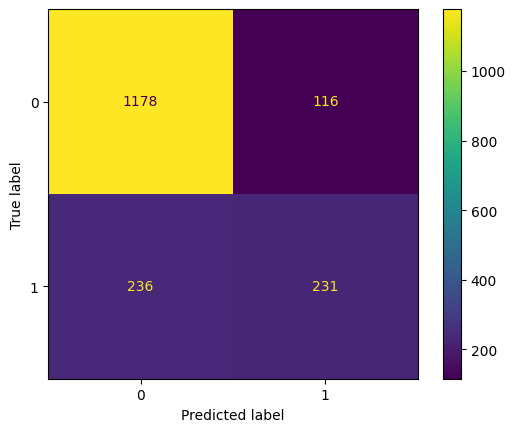

In [50]:
# XGB Confusion matrix
log_cm = confusion_matrix(y_test, y_pred_xgb, labels=xgb_cv.classes_)

log_disp = ConfusionMatrixDisplay(confusion_matrix=log_cm, display_labels=xgb_cv.classes_)
log_disp.plot(values_format='')

<Axes: title={'center': 'Feature importance'}, xlabel='Importance score', ylabel='Features'>

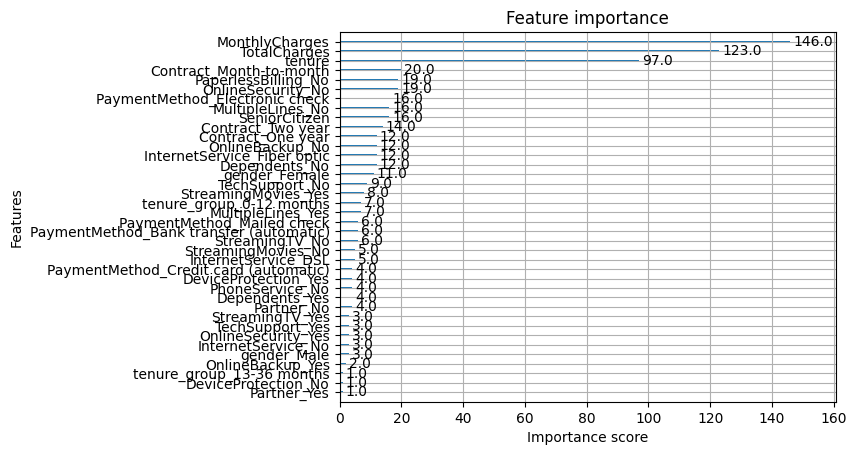

In [51]:
# Plot the relative feature importance of the predictor variables in the model
plot_importance(best_xgb)

In [52]:
results = pd.concat([
    results,
    make_results('XGBoost', y_test, y_pred_xgb)], ignore_index=True)

print(results.round(3))

                 Model     F1  Recall  Precision  Accuracy
0  Logistic Regression  0.580   0.522      0.651     0.799
1        Random Forest  0.562   0.495      0.651     0.796
2              XGBoost  0.568   0.495      0.666     0.800


The Logistic Regression model performs best for our churn detection objective, achieving the highest recall (52.2%) and F1-score (0.580). XGBoost achieves slightly higher precision (66.6%) and accuracy (80.0%), but its recall is lower (49.5%). Since identifying as many potential churners as possible is our main objective, Logistic Regression is the preferred model among the three, although the performance differences are relatively small.

## Conclusion and Business Recommendations

Our exploratory data analysis shows that customers with shorter tenure (0–12 months), month-to-month contracts, and higher monthly charges tend to have higher churn rates. Customers without online security or technical support services also show higher churn rates.

After training and evaluating three classification models, Logistic Regression emerged as the most suitable model for our churn detection objective, achieving a recall of 52.2%, a precision of 65.1%, and an accuracy of 79.9%. It also achieved the highest F1-score among the three models tested.

Although the model identifies approximately 52% of customers who actually churn, there is still room for improvement.

**Business recommendations:**
- Monitor customers with month-to-month contracts more closely, particularly those with short tenure.
- Explore targeted offers for online security and technical support services as potential retention strategies.
- Consider targeted retention offers for customers identified as being at high risk of churn.

**Next steps:**

The next step would be to evaluate different classification thresholds to determine whether recall can be improved while maintaining an acceptable precision level. The business should also assess the cost-effectiveness of retention campaigns to determine whether these interventions actually reduce churn.

A future project could involve conducting customer surveys to better understand customer needs, reasons for dissatisfaction, and potential areas for service improvement.

